# Multiheight inline phase recovery: active reconstruction review


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 观测到目标核查卡

当前存在 `data/raw_data.npz`；所述获取/估计路径由本地代码实现。

任务 `multiheight_inline_phase_recovery` 的观测定义：当前raw_data.npz的实际键、形状、dtype与README单位说明：measurements (1, 8, 512, 512) uint16：Author supplied simulated detector images, digital counts [DN], ordered by increasing distance.。恢复目标：complex object-plane optical field，normalized amplitude与phase。

获取模型：angular-spectrum传播后取强度，八个defocus平面约束共同复场。实际恢复算法：solvers.reconstruct顺序往返propagation与幅度投影，标准100循环。语义类型为 `inverse_spatial`；其中闭式逆也属于反问题，但内部制造观测或缺输入的限制见下文。

真值情况：数值方法参考，不能当作独立物理真值；test/validation.md:12/81虽为作者simulation但未给独立object truth；baseline是原始重建场。评估方法参考与仪器校准均不能当作独立物理真值。

现有实验和图：multiheight_inline_phase_recovery.ipynb单元6：5. Results；Measured results and comparison provenance；Spatial reconstructions, residuals and ablation；multiheight_inline_phase_recovery.ipynb单元9有保存图；图内容由该单元调用的本地visualization函数生成。图/比较代码位于单元9（从0计数）。代码单元4个，带execution_count的4个，保存PNG输出4幅；本审计未重新运行。

现有输出来自历史执行；本次未复跑。

限制与缺口：本次为静态语义与证据核查，未重新验证数值正确性或运行结果。

<!-- inverse-evidence-audit:20261026:end -->



## 1. Problem

Recover a complex object-plane optical field from eight defocused intensity-only images. Phase is encoded through propagation but an arbitrary spatially constant phase remains unobservable.

The physical unknown is a spatial complex optical field, reconstructed from eight defocused intensity-only images. The bound TIFFs are **existing author simulations**, not real measured observations. This review reconstructs all planes through cleaned local mathematics. Frozen modern upstream results are explicitly labeled and serve only as comparisons, not as actual truth.

Pedrini, Osten & Zhang (Optics Letters 2005, DOI10.1364/OL.30.000833) describes the forward/reverse multi-plane amplitude-constraint method. Raindoss Fringe is the separately authored modern MIT implementation supplying this dataset. We reproduce its official NumPy backend, not the original paper authors' code or paper numerical figures.


## 2. Data

The existing author simulations use a 512 by 512 grid, wavelength 0.532 micrometres, pitch 1.12 micrometres and distances 300 to 650 micrometres. Float32 camera normalization and quantization are retained. Independent object truth is unavailable; the modern upstream result is a method reference.

| Key | Shape | Dtype | Description |
|---|---|---|---|
| measurements | (1, 8, 512, 512) | uint16 | Author supplied simulated detector images, digital counts [DN], ordered by increasing distance. |

**Acquisition metadata**

| Parameter | Value | Unit | Meaning |
|---|---|---|---|
| Wavelength | 0.532 | μm | Monochromatic wavelength in the homogeneous medium. |
| Pixel spacing | 1.12 | μm | Same transverse sampling along y and x. |
| Detector distances | 300, 350, 400, 450, 500, 550, 600, 650 | μm | Positive object-to-detector axial displacement, in input plane order. |
| Camera scale | 65535 | DN | Divisor for archived 16-bit observations. |
| Axes | plane, y, x | index | Plane-major detector array after batch axis. |
| Boundary | periodic | — | Discrete Fourier propagation without padding. |
| Illumination | coherent, monochromatic | — | Scalar optical wave model. |
| Normalization | per-plane spatial-minimum subtraction and division by one minus minimum | dimensionless | Defined explicitly in Problem Description. |
| Noise | no calibrated stochastic noise model supplied | — | Existing author simulations include stored quantization; no noise variance is assumed. |


In [1]:
from pathlib import Path
import os,sys,time,json
import numpy as np
import matplotlib.pyplot as plt
root=Path.cwd()
if not (root/'src').exists():root=root.parent
sys.path.insert(0,str(root))
from src.preprocessing import load_data,amplitude_stack,DISTANCES
from src.solvers import reconstruct
from src.physics_model import amplitude_residual
from src.visualization import figure_groups
start=time.perf_counter()
raw=load_data(root/'data/raw_data.npz')
a=amplitude_stack(raw)
print('Bound observations:',raw.shape,raw.dtype,'distances [ um]:',DISTANCES)


Bound observations: (8, 512, 512) uint16 distances [ um]: [300. 350. 400. 450. 500. 550. 600. 650.]


## 3. Physics

The periodic scalar angular-spectrum relation below defines the propagator, field, intensity and signed distance conventions. All sampled frequencies propagate at this pitch/wavelength, so the modeled transfer is a unit-modulus phase factor rather than an evanescent-mode recovery.

### Physics and algorithm

Let $u(y,x)$ denote object field, $I_j$ normalized measured intensity, $z_j$ positive detector distance, $k=2\pi/\lambda$ optical wave number, and $q_x,q_y$ angular spatial frequencies. The scalar periodic angular-spectrum model is


$$
I_j=|\mathcal P_{z_j}u|^2,\quad \mathcal P_z u=\mathcal F^{-1}[e^{iz\sqrt{k^2-q_x^2-q_y^2}}\mathcal F u].
$$


Wavelength is .532 um and pixel spacing1.12 um; all sampled frequencies propagate. Camera normalization matches the upstream modifiers: float32 division by65535, per-plane minimum subtraction and division by one minus minimum, then square root. This retained normalization and quantization cause a nonzero residual.

Initialize with first-plane measured amplitude and zero phase. Each step propagates to the next plane, then replaces only its amplitude. A reverse sweep returns to the first plane;100 complete sweeps are followed by object-plane backpropagation. There is no spatial regularizer or ground-truth-informed tuning. Float64 NumPy signed distances preserve the validated reference precision. This nonconvex algorithm has no guarantee of a unique optimum.

The next cell actively computes the benchmark and two scientifically informative comparisons. The two-plane method uses only the first and last input observations; all results are evaluated against all eight planes.


## 4. Method

The local forward/reverse amplitude-projection method starts with first-plane amplitude and zero phase, runs 100 full sweeps and backpropagates to the object plane. Single-plane and two-plane controls are computed separately; no hidden object prior or target-based tuning initializes the field.

Use a multi-distance amplitude-projection method. Propagate a field between neighboring detector planes, preserve its computed phase, and replace its amplitude with the square root of that plane's measured normalized intensity. A forward traversal followed by a reverse traversal shares the phase information across the planes. Finally propagate back to the object plane. Consistent Fourier signs, physical distance units and numerical precision matter over many traversals.


## 5. Results

The active path reconstructs all eight planes and evaluates every variant against all observations. Retain amplitude/phase maps, all-plane residuals, convergence and plane-count ablation. Only a single constant phase can be aligned in complex reference metrics; no image shift or amplitude fit is allowed.

### Measured results and comparison provenance

The frozen reference below was produced by running the modern upstream implementation twice on these exact observations. Both runs were bitwise identical. The fresh field has just been computed above. A single spatially constant phase may be aligned because all intensities are invariant under that phase; no amplitude, translation or spatial phase alignment is allowed.

Complex NCC is absolute cosine similarity; complex NRMSE is RMS complex error after constant-phase alignment divided by reference amplitude range. Observation residual is the L2 amplitude mismatch across all eight planes divided by measured amplitude norm. The standalone Judge implements these metrics independently of solver modules. No archived paper metrics are relabeled as fresh measurements.

### Spatial reconstructions, residuals and ablation

Four figure groups retain the source notebook's single-plane and multi-plane amplitude/phase comparisons and extend them with all input planes, independent upstream parity, all-plane residual maps, convergence and plane-count ablation. Wrapped phase is shown in radians, not mislabeled as absolute optical path or unwrapped phase. There is no independently known object truth, so differences from the standard reference are numerical fidelity, not physical accuracy.


In [2]:
fresh,history=reconstruct(a,iterations=100)
single,_=reconstruct(a,iterations=0)
two,_=reconstruct(a[[0,7]],iterations=30,distances=DISTANCES[[0,7]])
upstream=np.load(root/'notebooks/reference_outputs/upstream_reconstruction.npz',allow_pickle=False)['reconstruction'][0]
elapsed=time.perf_counter()-start
np.savez_compressed(root/'output/reconstruction.npz',reconstruction=fresh[None])
print(f'Active full reconstruction plus comparisons: {elapsed:.3f} s')


Active full reconstruction plus comparisons: 51.569 s


In [3]:
import importlib.util
spec=importlib.util.spec_from_file_location('independent_judge',root/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
rows=[]
for name,u in [('Fresh single-plane',single),('Fresh two-plane (30 sweeps)',two),('Fresh eight-plane (100 sweeps)',fresh),('Reproduced upstream eight-plane',upstream)]:
    m=judge.compare(u,upstream);m['amplitude_residual']=amplitude_residual(u,a,DISTANCES)
    rows.append({'method':name,**m})
print(json.dumps(rows,indent=2))
report=judge.evaluate(root/'output/reconstruction.npz');print(json.dumps(report,indent=2));assert report['passed']


[
  {
    "method": "Fresh single-plane",
    "ncc": 0.5994134624651879,
    "nrmse": 0.3545358722110113,
    "amplitude_residual": 0.23614168183815068
  },
  {
    "method": "Fresh two-plane (30 sweeps)",
    "ncc": 0.6390554470369764,
    "nrmse": 0.3365365652627849,
    "amplitude_residual": 0.25119874446444085
  },
  {
    "method": "Fresh eight-plane (100 sweeps)",
    "ncc": 0.9999999999999974,
    "nrmse": 0.0,
    "amplitude_residual": 0.06764432302086348
  },
  {
    "method": "Reproduced upstream eight-plane",
    "ncc": 0.9999999999999974,
    "nrmse": 0.0,
    "amplitude_residual": 0.06764432302086348
  }
]


{
  "status": "pass",
  "passed": true,
  "metrics": {
    "ncc": 0.9999999999999974,
    "nrmse": 0.0,
    "amplitude_residual": 0.06764432292810817
  },
  "thresholds": {
    "ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "nrmse": {
      "comparison": "<=",
      "boundary": 0.0001
    },
    "amplitude_residual": {
      "comparison": "<=",
      "boundary": 0.06832026206177774
    }
  },
  "errors": []
}


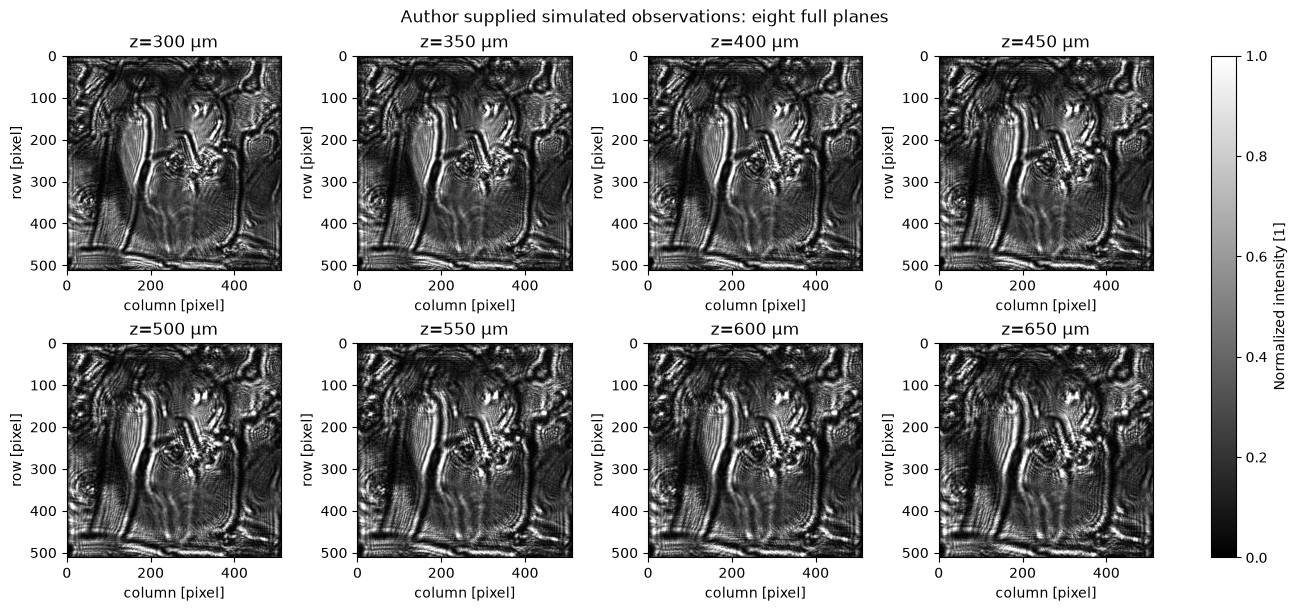

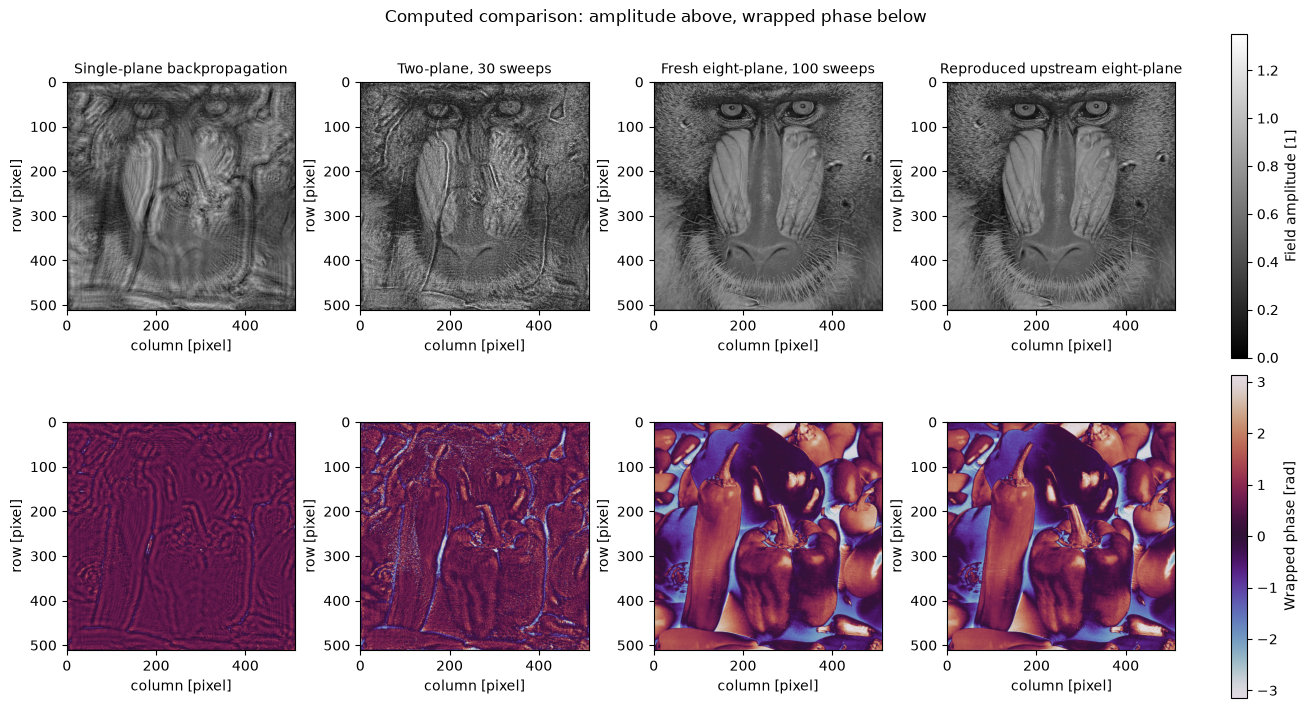

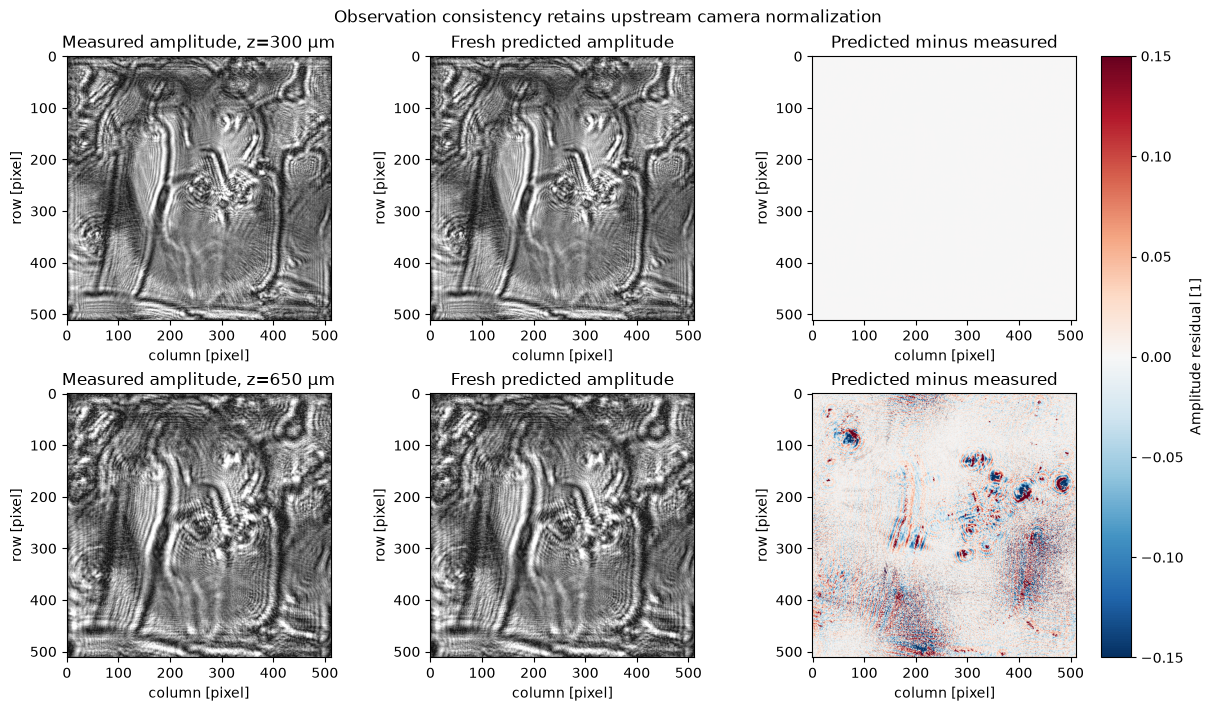

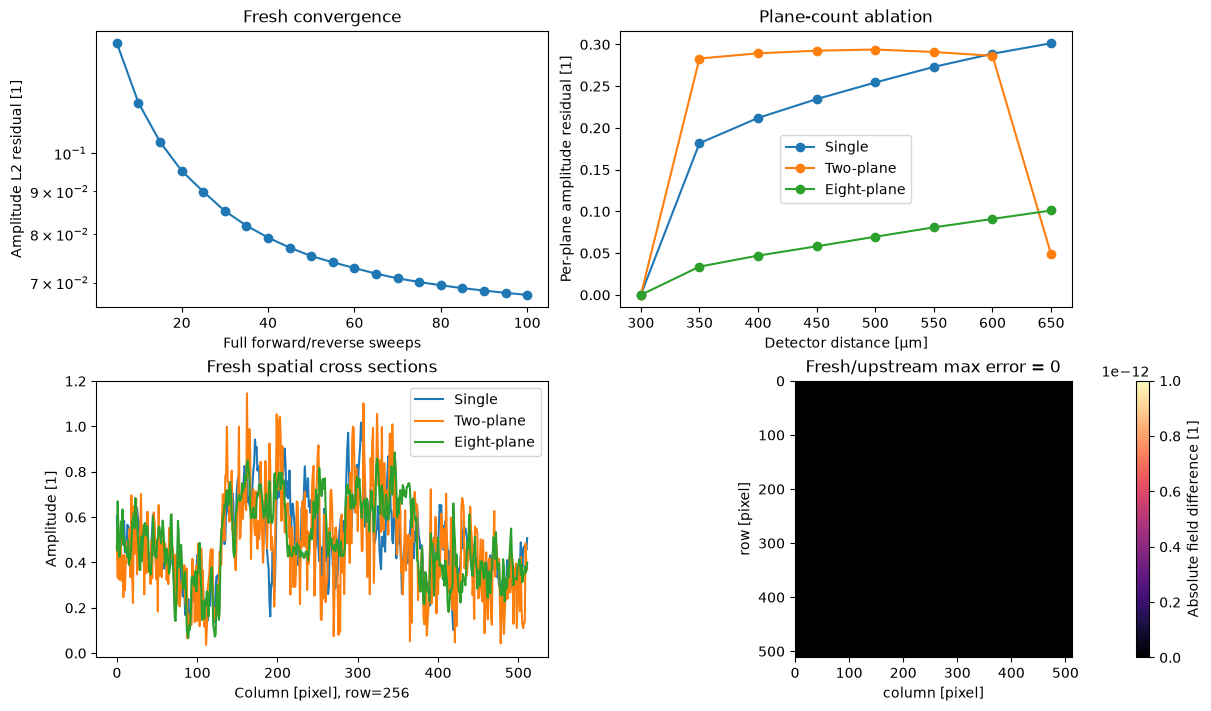

Figure groups: ['observations', 'reconstructions', 'residual_maps', 'diagnostics']


In [4]:
figs=figure_groups(a,fresh,upstream,single,two,history,export=os.environ.get('PRIVATE_FIGURES'))
for name,fig in figs:
    display(fig)
    plt.close(fig)
print('Figure groups:',[name for name,_ in figs])


## 6. Conclusion

The recorded agreement supports the selected modern implementation and shows the contribution of multiple defocus constraints. Nonconvex ambiguity and nonzero normalization residual remain; simulated data and method agreement do not establish experimental or unique object truth.

### Interpretation and limitations

Multiple defocus planes transfer phase information through repeated magnitude constraints. The fresh eight-plane result agrees with the independently reproduced modern standard implementation while retaining its nonzero camera-normalization residual. The two-plane ablation and single-plane backpropagation expose the information gained from the additional measurements; their errors are computed, not filled from cached references.

Passing the Judge verifies the declared reconstruction interface, reproducibility and observation consistency. It does not establish uniqueness, correctness of the author's simulation object, or experimental performance. The dataset provides no independent truth array. No field reconstruction has been labeled ground truth.
